# Composition scaling demo

`mode="composition_scaling"` in `phase_diagram_workflows`: part of the atoms of a structure are alchemically turned into another species (the interaction is switched from one potential to the other, forward and backward), with Monte Carlo identity-exchange swaps between MD blocks that sample which atoms are the transformed ones (`monte_carlo.use_custom_lammps=True` needs the `thermoatoms/lammps` fork).

**The results have only the free-energy difference ΔF to the starting composition (`delta_free_energy`), not the free energy F itself: there is no `free_energy` column.** F(target) = F(start) + ΔF. The free energy of the starting composition comes from a separate calculation (for example `mode="fe"` for the starting structure), and adding it is left to you (last section).

LAMMPS is driven through `pylammpsmpi` (`execution_mode="library"`); calphy builds and owns its LAMMPS session. The step counts are small, chosen to keep this demo fast: the result is not converged. For converged values see Menon et al. 2026, Sec. 2.2 (250 000 swap attempts, 25 ps of switching).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt

# Add project root to path for imports
PROJECT_ROOT = next(
    (parent for parent in [Path.cwd(), *Path.cwd().parents] if (parent / "pyproject.toml").is_file()),
    Path.cwd(),
)
SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from phase_diagram_workflows.free_energies import ti_calculator as calphy_calc
from phase_diagram_workflows.free_energies.plotting import plot_forward_backward_composition_scaling

EXAMPLE_ROOT = PROJECT_ROOT / "notebooks" / "Aluminium_composition_scaling"   # results; ignored by git

In [2]:
from ase.build import bulk
from lammpsparser import get_potential_by_name
import pandas as pd

## 1. Structure and potential

In [3]:
# pure Al: the starting composition
Al_pure_structure = bulk('Al', cubic=True).repeat(4)
N_ATOMS = len(Al_pure_structure)
print(f"Created Al structure with {N_ATOMS} atoms")

Created Al structure with 256 atoms


In [4]:
# an Al-Mg EAM potential
potential_df = get_potential_by_name('2009--Mendelev-M-I--Al-Mg--LAMMPS--ipr1')
potential_df = potential_df.to_frame().transpose()
display(potential_df.head())

/cmmc/ptmp/pchilaka/mamba/envs/lammps_mdmc/lib/python3.12/site-packages/lammpsparser/potential.py:326: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_pot["Config"] = config_lst


,Config,Filename,Model,Name,Species,Citations
164,"[pair_style eam/fs, pair_coeff * * /cmmc/ptmp/...",[potential_LAMMPS/2009--Mendelev-M-I--Al-Mg--L...,NISTiprpy,2009--Mendelev-M-I--Al-Mg--LAMMPS--ipr1,"[Al, Mg]",[{'Mendelev_2009': {'title': 'Development of i...


## 2. The calculation

Turns 5 of the 256 Al atoms into Mg (c(Mg) = 5 / 256 = 0.0195) at 300 K. `reference_composition` is c(Mg) of the starting structure (pure Al: 0). The atomic masses are taken from ase for every species of the potential.

In [5]:
N_MG_TARGET = 5

input_params_cs = {
    "mode": "composition_scaling",
    "temperature": 300,
    "n_equilibration_steps": 5000,
    "n_switching_steps": 5000,
    "n_print_steps": 500,
    "equilibration_control": "nose-hoover",
    "execution_mode": "library",
    "queue": {"cores": 1, "scheduler": "local"},
    'reference_phase': 'solid',
    'file_format': 'lammps-data',
    'reference_composition': 0.0,
    'composition_scaling': {
        'output_chemical_composition': {'Al': N_ATOMS - N_MG_TARGET, 'Mg': N_MG_TARGET},
    },
    'monte_carlo': {
        'n_steps': 20,       # MD steps between two blocks of swaps
        'n_swaps': 20,       # attempted swaps per block
        'use_custom_lammps': True,
    },
}

In [6]:
WORKING_DIRECTORY = str(EXAMPLE_ROOT / "Al_composition_scaling")
print("Running the composition_scaling calculation...")
calculation, results = calphy_calc.calc_free_energy_with_calphy(
    input_structure=Al_pure_structure,
    potential_df=potential_df,
    calphy_parameters=input_params_cs,
    working_directory=WORKING_DIRECTORY,
)
print("Calculation completed successfully!")

Running the composition_scaling calculation...
Input validation successful. Proceeding with calculation.


/cmmc/ptmp/pchilaka/mamba/envs/lammps_mdmc/lib/python3.12/site-packages/ase/io/lammpsdata.py:72: FutureWarning: "style" is deprecated; please use "atom_style".
  warnings.warn(
/cmmc/ptmp/pchilaka/mamba/envs/lammps_mdmc/lib/python3.12/site-packages/pydantic/main.py:475: UserWarning: Pydantic serializer warnings:
  PydanticSerializationUnexpectedValue(Unexpected Value)
  PydanticSerializationUnexpectedValue(Expected `list[float]` - serialized value may not be as expected [field_name='pressure', input_value=0, input_type=int])
  PydanticSerializationUnexpectedValue(Expected `list[list[float]]` - serialized value may not be as expected [field_name='pressure', input_value=0, input_type=int])
  return self.__pydantic_serializer__.to_python(


2026-10-19 16:15:20.390767: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


2026-10-19 16:15:38.793998: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Calculation completed successfully!


## 3. Results

**Only the difference ΔF is in the table, no absolute free energy.** One row, in eV/atom unless noted:

- `delta_free_energy`: the free-energy difference to the starting composition (work + mass correction), **without** the ideal-mixing term
- `ideal_entropy`: eV/atom/K, positive, as calphy has it; the ideal-mixing term is `-temperature * ideal_entropy`
- `delta_free_energy_with_ideal_entropy`: `delta_free_energy - temperature * ideal_entropy`
- `dissipation`: half the sum of the forward and backward work; about zero for a reversible switching
- `energy_target`: potential energy per atom of the target composition at the end of the forward switching

In [7]:
columns = ["calculation_mode", "temperature", "composition", "delta_free_energy", "ideal_entropy",
           "delta_free_energy_with_ideal_entropy", "dissipation", "energy_target"]
display(results[columns])

,calculation_mode,temperature,composition,delta_free_energy,ideal_entropy,delta_free_energy_with_ideal_entropy,dissipation,energy_target
0,composition_scaling,300.0,"{'Al': 0.98046875, 'Mg': 0.01953125}",0.039077,0.000008,0.03659,-0.000054,-3.332043


The whole table, as the function returns it, turned on its side (one row: the columns become a list). The columns that belong to the temperature-scaling mode are empty here.

In [8]:
display(results.T)

,0
calculation,Al_composition_scaling
calculation_mode,composition_scaling
reference_phase,solid
pressure,0
status,True
composition,"{'Al': 0.98046875, 'Mg': 0.01953125}"
temperature,300.0
reference_composition,0.0
delta_free_energy,0.039077
work,0.038998


### Forward and backward sweeps

U(target) - U(reference) per atom against lambda (1: starting composition, 0: target composition). The two sweeps lie on top of each other for a reversible switching; the gap between them is the dissipation, given in the title. In this small, easy case (5 of 256 atoms, a simple EAM potential, 300 K) the dissipation is tiny and the curves overlap.

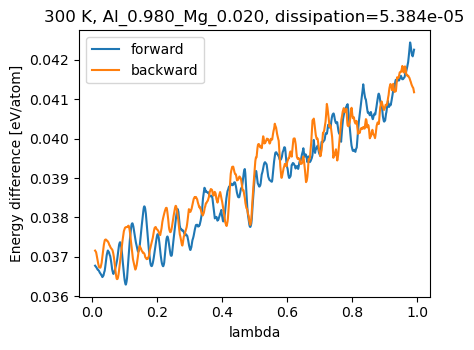

In [9]:
plot_forward_backward_composition_scaling(WORKING_DIRECTORY)
plt.show()

## 4. From ΔF to a free energy

F(target) = F(start) + `delta_free_energy`.

Get F(start) from a separate calculation of the starting structure at the same temperature and pressure, for example `mode="fe"` run with `calc_free_energy_with_calphy`, and add it to `delta_free_energy` yourself. Use `delta_free_energy_with_ideal_entropy` instead if you want the ideal-mixing term in.

The two calculations are independent: a composition-scaling job does not need the other one.